<a href="https://colab.research.google.com/github/anghelilinca/ML-Seminar_AnghelIlinca/blob/main/Anghel_Ilinca_Tema_Laborator_3_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [7]:
# TODO 1.1 — procentul de valori lipsă pe coloană
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("Procentul de valori lipsă pe coloană:")
print(missing_percentage.sort_values(ascending=False))

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
limit = 50.0
columns_to_drop = missing_percentage[missing_percentage > limit].index.tolist()
print(f"\nColoanele care vor fi eliminate (au >{limit}% valori lipsă): {columns_to_drop}")

df = df.drop(columns=columns_to_drop)
display(df.head())

Procentul de valori lipsă pe coloană:
deck        77.216611
age         19.865320
embarked     0.224467
sex          0.000000
pclass       0.000000
survived     0.000000
fare         0.000000
dtype: float64

Coloanele care vor fi eliminate (au >50.0% valori lipsă): ['deck']


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [8]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()
df['age'].fillna(df['age'].median(), inplace=True)
df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)

# TODO 2.2 — verificare + comparație deviație standard
missing_after = df.isnull().sum()
print("Valori lipsă după imputare:")
print(missing_after)

std_inainte = age_inainte.std()
std_dupa = df['age'].std()

print(f"\nDeviația standard a vârstei înainte de imputare: {std_inainte:.4f}")
print(f"Deviația standard a vârstei după imputare: {std_dupa:.4f}")

Valori lipsă după imputare:
survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64

Deviația standard a vârstei înainte de imputare: 14.5265
Deviația standard a vârstei după imputare: 13.0197


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness original (fare): 4.7873
Skewness transformat (log_fare): 0.3949


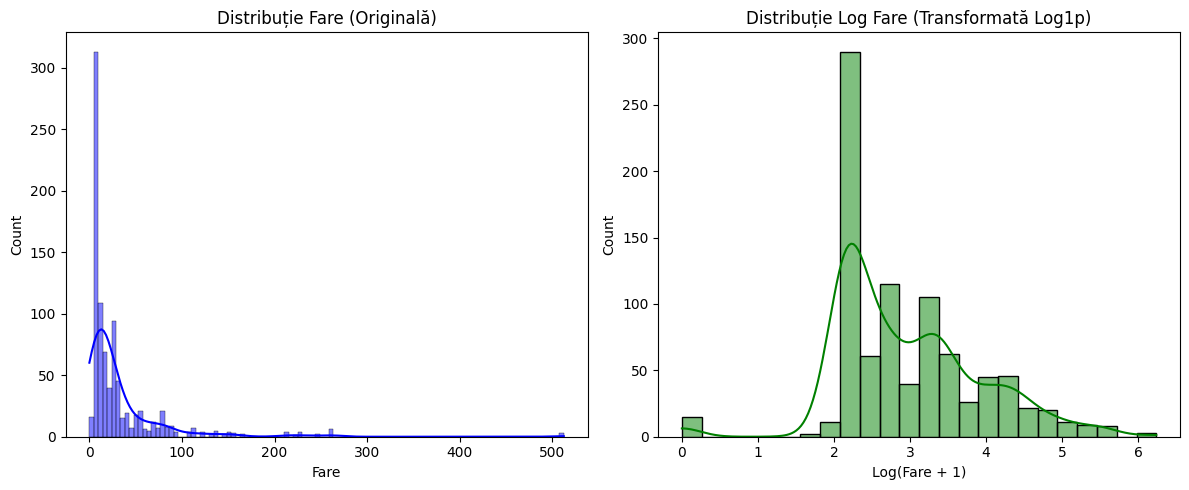

In [10]:
# TODO 3.1 — skewness fare
skew_fare = df['fare'].skew()
print(f"Skewness original (fare): {skew_fare:.4f}")

# TODO 3.2 — coloana log_fare + skewness
df['log_fare'] = np.log1p(df['fare'])
skew_log_fare = df['log_fare'].skew()
print(f"Skewness transformat (log_fare): {skew_log_fare:.4f}")

# TODO 3.3 — două histograme
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['fare'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribuție Fare (Originală)')
axes[0].set_xlabel('Fare')

sns.histplot(df['log_fare'], kde=True, ax=axes[1], color='green')
axes[1].set_title('Distribuție Log Fare (Transformată Log1p)')
axes[1].set_xlabel('Log(Fare + 1)')

plt.tight_layout()
plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [11]:
# TODO 4.1 — limite IQR + număr de outlieri
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df['fare'] < lower_limit) | (df['fare'] > upper_limit)]
print(f"Limita inferioară: {lower_limit:.4f}")
print(f"Limita superioară: {upper_limit:.4f}")
print(f"Număr total de outlieri: {len(outliers)}")

# TODO 4.2 — fare_capped (clip) + maxim înainte/după
df['fare_capped'] = df['fare'].clip(lower=lower_limit, upper=upper_limit)

print(f"\nValoarea maximă înainte de clip: {df['fare'].max():.4f}")
print(f"Valoarea maximă după clip (capped): {df['fare_capped'].max():.4f}")

Limita inferioară: -26.7240
Limita superioară: 65.6344
Număr total de outlieri: 116

Valoarea maximă înainte de clip: 512.3292
Valoarea maximă după clip (capped): 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [12]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
df = pd.get_dummies(df, columns=['sex', 'embarked'], drop_first=True, dtype=int)

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scaler = StandardScaler()
df[['age', 'fare_capped']] = scaler.fit_transform(df[['age', 'fare_capped']])

print("Media pentru age:", df['age'].mean())
print("Deviația standard pentru age:", df['age'].std())
print("\nMedia pentru fare_capped:", df['fare_capped'].mean())
print("Deviația standard pentru fare_capped:", df['fare_capped'].std())

print("\nPrimele rânduri din setul de date după encoding și scalare:")
display(df.head())

Media pentru age: 2.272779794518839e-16
Deviația standard pentru age: 1.000561640033049

Media pentru fare_capped: 9.968332432100171e-17
Deviația standard pentru fare_capped: 1.0005616400330448

Primele rânduri din setul de date după encoding și scalare:


,survived,pclass,age,fare,log_fare,fare_capped,sex_male,embarked_Q,embarked_S
0,0,3,-0.565736,7.2500,2.110213,-0.820552,1,0,1
1,1,1,0.663861,71.2833,4.280593,2.031623,0,0,0
2,1,3,-0.258337,7.9250,2.188856,-0.787578,0,0,1
3,1,1,0.433312,53.1000,3.990834,1.419297,0,0,1
4,0,3,0.433312,8.0500,2.202765,-0.781471,1,0,1


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*


Răspunsul tău:

Am imputat age deoarece are un procent rezonabil de valori lipsă (~20%), iar această variabilă este extrem de importantă pentru analiză, înlocuirea cu mediana menținând integritatea setului de date fără a distorsiona major distribuția.

Am eliminat deck deoarece procentul de valori lipsă este extrem de ridicat (peste 77%). Încercarea de a imputa o cantitate atât de mare de date ar fi introdus un nivel mult prea mare de incertitudine și zgomot artificial, făcând variabila nesigură și nefolositoare pentru modele.
